# Construir un ejemplo de aprendizaje para procesamiento de minerales

**Pregunta:** ¿Qué etiquetas físicas y errores de interpolación produce un Ridge pequeño entrenado con el simulador?

Nivel: 1. Requisitos previos: Ninguno; comenzar aquí. Tiempo de lectura: 20 minutos.


## Objetivos

Construir procedencia física de variables y objetivos y ajustar Ridge con partición 48/16 de 64 estados. Tres pruebas de casos establecen significado de etiquetas antes de examinar un modelo y una pregunta.

## Preparación

```bash
pip install numpy==2.2.6 scipy==1.17.1 pandas==2.2.3 matplotlib==3.11.2 nbclient==0.11.0 nbformat==5.11.1 ipykernel==7.4.0 SALib==1.6.0 scikit-learn==1.5.2 ruff==0.15.18 pytest==9.1.1
```

El pipeline OreFlow se importa desde `data-pipeline/`; este notebook nunca instala paquetes.

Importar las herramientas fijadas y resolver las entradas relativas a la carpeta del notebook.

In [1]:
# Importar herramientas de análisis y registrar sus versiones exactas.
import importlib.metadata
import json
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

repo = Path("../../../").resolve()
sys.path.insert(0, str(repo / "data-pipeline"))
for package in ("numpy", "scipy", "pandas", "matplotlib", "nbclient", "nbformat", "ipykernel"):
    print(package, importlib.metadata.version(package))
legend_style = dict(loc="lower center", bbox_to_anchor=(0.5, 1.02), frameon=False)


numpy 2.2.6
scipy 1.17.1
pandas 2.2.3
matplotlib 3.11.2
nbclient 0.11.0
nbformat 5.11.1
ipykernel 7.4.0


## Datos

Responsable: autores de OreFlow, licencia MIT. Se lee `data/derived/contract/operating_contract.json` y el catálogo aporta cuatro definiciones de casos. `build_design` genera 64 etiquetas mediante el motor de circuito. No se leen puntuaciones de learning.json ni modelos desplegados. Estados y factores minerales son entradas sintéticas del modelo, no mediciones inventadas. Fuente: https://github.com/fsantibanezleal/CAOS_OreFlow.

## Método

La primera regresión ajusta solo recuperación. Cuatro casos aportan dieciséis estados cada uno; las variables describen mineral y operación sin identificador de caso explícito. Ridge aprende con 48 filas después de ajustar StandardScaler solo en ellas. Dieciséis filas reservadas aportan RMSE, MAE y R2. Tres resoluciones nominales establecen procedencia de etiquetas. Las propiedades pueden codificar identidad indirectamente; esta prueba es interpolación entre casos representados, no otra población mineral.

Crear un primer conjunto supervisado con sesenta y cuatro resoluciones acotadas. Cuatro circuitos aportan dieciséis estados cada uno. Las variables describen mineral y operación sin incluir identificador de caso. Los objetivos son recuperación, enriquecimiento logarítmico y energía total. Aquí se ajusta solo recuperación, una tarea comprensible que muestra de dónde provienen las otras etiquetas. El generador respeta contrato y usa semilla fija para repetir el diseño.

In [2]:
# Construir el diseño de aprendizaje desde las salidas físicas del circuito.
from pipeline.cases.catalog import CASE_BY_ID
from pipeline.engine.circuit import simulate
from pipeline.methods.learning import build_design, interpolation_split, leave_one_case_out
from pipeline.methods.learning import leave_one_group_out, transfer_groups, FEATURES, TARGETS
import contextlib
import io

contract = json.loads((repo / "data/derived/contract/operating_contract.json").read_text(encoding="utf-8"))
case_ids = ("copper_porphyry_soft", "copper_porphyry_hard", "copper_oxide", "iron_magnetite_fine")
selected = tuple((CASE_BY_ID[name] for name in case_ids))
with contextlib.redirect_stdout(io.StringIO()):
    design = build_design(contract, cases=selected, per_case=16, seed=20261031)
x, y, case_of = (design["x"], design["y"], design["case"])
print("Filas del diseño:", len(x))
print("Variables:", len(FEATURES))
print("Objetivos:", TARGETS)


Filas del diseño: 64
Variables: 22
Objetivos: ('recovery_pct', 'log_upgrade', 'specific_energy_total_kwh_t')


Inspeccionar directamente una etiqueta nominal del pórfido blando. Recuperación es fracción de material valioso recuperado; energía específica se normaliza por masa tratada. El aprendiz recibe una salida solo si la eliges como objetivo: aquí recuperación. Resolver por separado demuestra procedencia física antes de entregar matrices al estimador. También establece que entrenamiento no oculta una respuesta medida de planta.

In [3]:
# Inspeccionar la etiqueta nominal de `copper_porphyry_soft` antes de agrupar sus filas.
case = CASE_BY_ID["copper_porphyry_soft"]
point = case.nominal
reference = simulate(case.ore, case.plant, point)
print("Caso de referencia:", case.id)
print("Recuperación de referencia (%):", round(reference.metrics["recovery_pct"], 3))
print("Energía de referencia (kWh/t):", round(reference.metrics["specific_energy_total_kwh_t"], 3))


Caso de referencia: copper_porphyry_soft
Recuperación de referencia (%): 92.213
Energía de referencia (kWh/t): 10.395


Resolver cobre oxidado con su propia definición nominal. Sus propiedades difieren del pórfido; configuraciones operativas cercanas no implican etiquetas cercanas entre casos. Aunque falta el identificador, las propiedades físicas pueden codificar señales fuertes de identidad. Por eso una buena prueba aleatoria por filas no equivale automáticamente a generalizar a un mineral desconocido.

In [4]:
# Inspeccionar la etiqueta nominal de `copper_oxide` antes de agrupar sus filas.
case = CASE_BY_ID["copper_oxide"]
point = case.nominal
reference = simulate(case.ore, case.plant, point)
print("Caso de referencia:", case.id)
print("Recuperación de referencia (%):", round(reference.metrics["recovery_pct"], 3))
print("Energía de referencia (kWh/t):", round(reference.metrics["specific_energy_total_kwh_t"], 3))


Caso de referencia: copper_oxide
Recuperación de referencia (%): 76.539
Energía de referencia (kWh/t): 11.263


Calcular magnetita con su diagrama de separación, sin imponer un modelo exclusivo de flotación. El vector incluye indicadores de etapas instaladas. Comparar la etiqueta con los ejemplos de cobre enseña el alcance de una representación común. Unidades de recuperación compartidas permiten un objetivo de regresión, pero no vuelven idénticos los mecanismos minerales y de separación.

In [5]:
# Inspeccionar la etiqueta nominal de `iron_magnetite_fine` antes de agrupar sus filas.
case = CASE_BY_ID["iron_magnetite_fine"]
point = case.nominal
reference = simulate(case.ore, case.plant, point)
print("Caso de referencia:", case.id)
print("Recuperación de referencia (%):", round(reference.metrics["recovery_pct"], 3))
print("Energía de referencia (kWh/t):", round(reference.metrics["specific_energy_total_kwh_t"], 3))


Caso de referencia: iron_magnetite_fine
Recuperación de referencia (%): 84.952
Energía de referencia (kWh/t): 20.167


Reserva un cuarto de las filas de cada caso mediante el particionador de interpolación. Entrenamiento y prueba contienen los cuatro casos: se pregunta por estados nuevos de circuitos ya representados. El inventario impreso revela el límite antes de puntuar. Escala dentro del entrenamiento; usar medias del diseño completo introduciría información de prueba en la representación aun sin filtrar una etiqueta objetivo.

In [6]:
# Construir tres preguntas de validación sobre exactamente el mismo diseño.
train, test = interpolation_split(case_of, test_fraction=0.25, seed=20261031)
case_fold = next((f for f in leave_one_case_out(case_of) if f[0] == "copper_porphyry_soft"))
group_fold = leave_one_group_out(case_of, transfer_groups(selected))[0]
splits = {
    "Interpolación": (train, test),
    "Caso reservado": case_fold[1:],
    "Grupo mineral reservado": group_fold[1:],
}
for protocol, (training, testing) in splits.items():
    print(protocol, len(training), len(testing))
    print("Casos de entrenamiento:", sorted(set(case_of[training].tolist())))
    print("Casos de prueba:", sorted(set(case_of[testing].tolist())))
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

scores, predictions = ([], {})
splits = {list(splits)[0]: next(iter(splits.values()))}


Interpolación 48 16
Casos de entrenamiento: ['copper_oxide', 'copper_porphyry_hard', 'copper_porphyry_soft', 'iron_magnetite_fine']
Casos de prueba: ['copper_oxide', 'copper_porphyry_hard', 'copper_porphyry_soft', 'iron_magnetite_fine']
Caso reservado 48 16
Casos de entrenamiento: ['copper_oxide', 'copper_porphyry_hard', 'iron_magnetite_fine']
Casos de prueba: ['copper_porphyry_soft']
Grupo mineral reservado 32 32
Casos de entrenamiento: ['copper_oxide', 'iron_magnetite_fine']
Casos de prueba: ['copper_porphyry_hard', 'copper_porphyry_soft']


Ajustar Ridge después de estandarizar solo con entrenamiento y predice las etiquetas reservadas. La penalización estabiliza un ajuste lineal con variables correlacionadas. Conservar alpha fijo, sin buscarlo con puntuaciones de prueba. Calcular RMSE, MAE y R² desde predicciones. Un R² negativo indica peor desempeño que la referencia de media de prueba y es informativo; no justifica ocultar el pliegue.

In [7]:
# Ridge penaliza los coeficientes al cuadrado después de escalar.
for protocol, (training, testing) in splits.items():
    model = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
    model.fit(x[training], y[training, 0])
    predicted = model.predict(x[testing])
    print("Rango de predicción (%):", np.round([predicted.min(), predicted.max()], 3))
    print("Rango de referencia (%):", np.round([y[testing, 0].min(), y[testing, 0].max()], 3))
    predictions["Ridge", protocol] = (testing, predicted)
    scores.append(
        {
            "Modelo": "Ridge",
            "Protocolo": protocol,
            "RMSE (pp)": float(np.sqrt(mean_squared_error(y[testing, 0], predicted))),
            "MAE (pp)": float(mean_absolute_error(y[testing, 0], predicted)),
            "R2": float(r2_score(y[testing, 0], predicted)),
        }
    )
display(pd.DataFrame(scores).tail(3).round(3))


Rango de predicción (%): [ 60.496 103.466]
Rango de referencia (%): [50.979 93.623]


,Modelo,Protocolo,RMSE (pp),MAE (pp),R2
0,Ridge,Interpolación,11.581,9.819,0.055


Dibujar el error de interpolación de este único estimador. La lección inicial contiene un protocolo y un modelo ajustado; la barra resume una predicción concreta, no una clasificación bibliográfica. Usar puntos porcentuales porque mide diferencias de recuperación, no cambio porcentual relativo. Leer junto a rangos de predicción y referencia para juzgar la magnitud.

Filas RMSE calculadas: 1


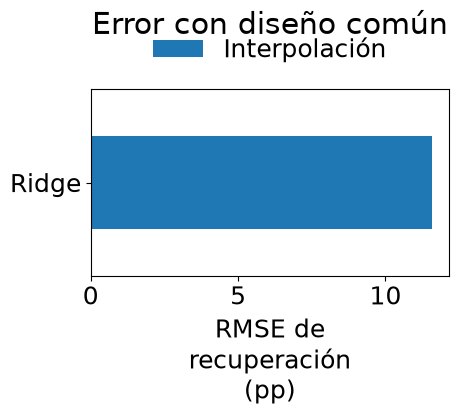

In [8]:
# Comparar el RMSE de recuperación dentro de cada pregunta de validación.
plt.rcParams.update({"font.size": 18, "axes.titlepad": 40})
score = pd.DataFrame(scores)
fig, ax = plt.subplots(figsize=(6.4, 3.8))
score.pivot(index="Modelo", columns="Protocolo", values="RMSE (pp)").plot.barh(ax=ax)
ax.set(xlabel="RMSE de\nrecuperación\n(pp)", ylabel="", title="Error con diseño común")
ax.tick_params(axis="x", rotation=0)
handles, legend_names = ax.get_legend_handles_labels()
legend_short = {"Caso reservado": "Caso", "Grupo mineral reservado": "Grupo mineral"}
ax.legend(
    handles,
    [legend_short.get(name, name) for name in legend_names],
    fontsize=18,
    ncol=2,
    **legend_style,
)
fig.subplots_adjust(left=0.4, right=0.96, bottom=0.23, top=0.72)
print("Filas RMSE calculadas:", len(score))


La barra es descriptiva y no tiene intervalo de confianza: se usa una partición determinista. Las sesenta y cuatro etiquetas comparten cuatro definiciones y no son observaciones geológicas independientes. El modelo aproxima el motor. Antes de agregar estimadores no lineales, confirmar unidades, representación de casos en ambas particiones y uso exclusivo de filas de entrenamiento al ajustar el estandarizador.

## Resultados

**Respuesta:** El diseño común contiene <!-- result:Filas del diseño -->64.0<!-- /result --> estados simulados. Ridge se ajusta con <!-- result:Filas de entrenamiento -->48.0<!-- /result --> filas y predice <!-- result:Filas de prueba interpolada -->16.0<!-- /result --> filas reservadas, con RMSE <!-- result:RMSE interpolado de Ridge (pp) -->11.581<!-- /result --> pp. Cada caso sigue representado en entrenamiento; se establece interpolación de etiquetas del motor, no predicción de mineral ausente ni planta medida.

Resumir cantidades reales de diseño, entrenamiento y prueba interpolada junto al RMSE de recuperación de Ridge.

In [9]:
# Resumir las salidas calculadas que sostienen la interpretación de esta lección.
score_by_key = {(row["Modelo"], row["Protocolo"]): row for row in scores}
answer_values = {
    "Filas del diseño": len(x),
    "RMSE interpolado de Ridge (pp)": score_by_key["Ridge", "Interpolación"]["RMSE (pp)"],
}
answer_values.update({"Filas de entrenamiento": len(train), "Filas de prueba interpolada": len(test)})
answer_values = {label: round(float(number), 3) for label, number in answer_values.items()}
print(json.dumps(answer_values, ensure_ascii=False))


{"Filas del diseño": 64.0, "RMSE interpolado de Ridge (pp)": 11.581, "Filas de entrenamiento": 48.0, "Filas de prueba interpolada": 16.0}


## Resumen

El ajuste inicial usa 48 filas para predecir dieciséis reservadas dentro de 64 estados. Procedencia y unidades preceden cualquier orden de modelos. En esta pregunta de interpolación no falta un caso mineral al entrenar.

### Qué representan las filas antes de ajustar un modelo

El diseño se genera al resolver el circuito físico de OreFlow en estados operacionales controlados. Cada fila es un vector de entradas emparejado con una respuesta del simulador; no es una medición independiente de planta. Las variables describen factores operacionales y del mineral, mientras que las columnas objetivo incluyen respuestas de recuperación y energía. Antes de ajustar un modelo, revisa cuántos estados aporta cada caso y mantén el identificador de caso fuera de la matriz predictiva. El identificador sirve para separar y auditar; incluirlo como variable permitiría memorizar una etiqueta de caso en vez de aprender una relación de proceso transferible.

Las distribuciones por caso de la figura muestran directamente las etiquetas del diseño. Las diferencias entre medianas pueden deberse a mineralogía, configuración de planta o controles muestreados. La dispersión dentro de un caso proviene del diseño operacional declarado. No conviene comprimir esas fuentes de variación en una sola afirmación sobre exactitud. Una partición de interpolación deja estados relacionados de un caso conocido a ambos lados; dejar un caso completo fuera pregunta si el modelo transfiere a otro caso creado; dejar fuera un grupo mineralógico examina una transferencia más amplia. Aunque compartan respuesta, son preguntas distintas.

Para un conjunto de prueba de tamaño $n$, el error cuadrático medio en raíz penaliza con más fuerza las predicciones muy alejadas que el error absoluto medio. Si la recuperación está en porcentaje, el RMSE queda expresado en puntos porcentuales. El coeficiente R² compara la variación residual con la varianza del conjunto de prueba y puede ser fuertemente negativo cuando el modelo rinde peor que la media de ese conjunto. Ninguna métrica se interpreta sola: deben acompañarla la unidad dejada fuera, el denominador, el rango objetivo y las reglas para predicciones rechazadas. Un buen resultado de interpolación no demuestra transferencia a otro grupo de mineral.

El diseño es sintético en sentido metodológico: OreFlow crea filas controladas llamando al motor de procesos. Esto hace reproducible la respuesta y permite estudiar una relación conocida, pero no incorpora la geología no modelada, los errores de medición ni las intervenciones que existen en datos de planta. Los cuatro casos de esta introducción constituyen una muestra didáctica, no la evaluación completa de la versión. Para conclusiones sobre la versión debe consultarse el diseño mayor y los resultados con grupos retenidos del informe técnico.

Al leer la figura, observa primero el solapamiento y las diferencias de rango; después considera cualquier puntuación ajustada. Si un caso de prueba ocupa una región de respuestas o entradas ausente del entrenamiento, el modelo puede extrapolar. Una partición aleatoria de filas puede ocultarlo al repartir estados vecinos entre entrenamiento y prueba. La separación correcta depende de la pregunta de uso: predecir otro punto operacional de un caso conocido no equivale a predecir una nueva familia mineralógica. El cuaderno conserva esta distinción antes de ajustar Ridge.

### Trata cada fila como un experimento del simulador

El diseño se construye eligiendo entradas operacionales y resolviendo el circuito físico. Una fila empareja un vector de variables con una respuesta; no es un ensayo de laboratorio ni una medición independiente de planta. La respuesta proviene del simulador determinista actual, por lo que las mismas entradas y versión deben reproducir el objetivo dentro de la tolerancia numérica. Este entorno controlado permite comparar modelos y también limita su significado: el estimador aproxima las ecuaciones y casos creados de OreFlow, no descubre física de planta que el modelo no contiene.

La identidad de caso se conserva junto a cada fila porque define los grupos de evaluación. No debe entrar entre los predictores cuando la pregunta es transferir a un caso no observado. Si se incluye, el estimador puede explotar un atajo categórico y parecer exacto para etiquetas conocidas. Una partición aleatoria de filas solo sirve para una pregunta acotada de interpolación, donde estados operacionales vecinos pueden quedar en ambos lados. Dejar fuera un caso completo es una condición distinta y más difícil. Dejar fuera un grupo mineralógico pregunta si la relación ajustada cruza un límite mineralógico.

El diagrama de cajas añadido muestra las etiquetas de recuperación de la muestra didáctica de cuatro casos antes de ajustar un modelo. Cada caja resume estados del simulador generados para un caso; no representa incertidumbre de medición. La dispersión refleja las condiciones operacionales muestreadas y la respuesta del circuito. Medianas distintas pueden combinar efectos del mineral, planta y operación, porque este diseño introductorio no es un experimento factorial que aísle cada causa. Los rangos superpuestos se interpretan como motivo para revisar variables y grupos, no como prueba de que los casos sean intercambiables estadísticamente.

La primera métrica de error usada después es RMSE. Se calcula solo sobre las filas retenidas declaradas y conserva la unidad de la respuesta. Si recuperación está en porcentaje, un error de una unidad equivale a un punto porcentual. Los errores grandes pesan más porque los residuos se elevan al cuadrado antes de promediar. Informa RMSE junto con la unidad y el denominador de prueba; un número sin protocolo de partición no demuestra transferencia.

El cuaderno usa una muestra pequeña de cuatro casos para hacer inspeccionables tres conceptos de partición. No equivale a la evaluación de doce casos de la versión. Sus resultados no sustituyen el registro completo, y los casos elegidos no representan la diversidad de minerales operativos. En un estudio de campo, filas de una campaña pueden compartir sensores, operadores y condiciones; los grupos deben reflejar la unidad futura de despliegue. Antes de entrenar con datos propios, define esa unidad, conserva la columna de grupo fuera de las variables predictivas y ajusta el preprocesamiento solo con los pliegues de entrenamiento.

$$\operatorname{RMSE}=\sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat y_i)^2}$$

Aquí $y_i$ es una respuesta del simulador, $\hat y_i$ su predicción y $n$ la cantidad declarada de filas de prueba. La métrica hereda la unidad del objetivo y solo se interpreta junto con la partición y el grupo evaluado.

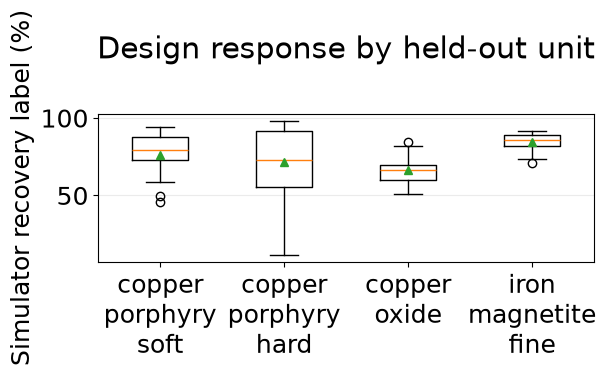

In [10]:
# Show the simulator-labelled recovery distribution by authored case.
frame = pd.DataFrame({"case": case_of, "recovery_pct": y[:, 0]})
fig, ax = plt.subplots(figsize=(6.4, 3.8))
labels = list(dict.fromkeys(frame["case"].tolist()))
series = [frame.loc[frame["case"] == label, "recovery_pct"].to_numpy() for label in labels]
ax.boxplot(series, tick_labels=[label.replace("_", "\n") for label in labels], showmeans=True)
ax.set(ylabel="Simulator recovery label (%)", title="Design response by held-out unit")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()


La segunda vista agrupa las mismas etiquetas por unidad de evaluación. La dispersión entre casos no es un intervalo de confianza y agrupar no crea menas independientes. Inspecciona el soporte de objetivos antes de puntuar: un caso reservado fuera del rango de entrenamiento plantea extrapolación, algo que las métricas de interpolación no contestan.

$$\operatorname{RMSE}=\sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat y_i)^2}$$

$y_i$ is the simulator response, $\hat y_i$ its prediction, and $n$ the held-out row count. The split defines the scope of the resulting error.

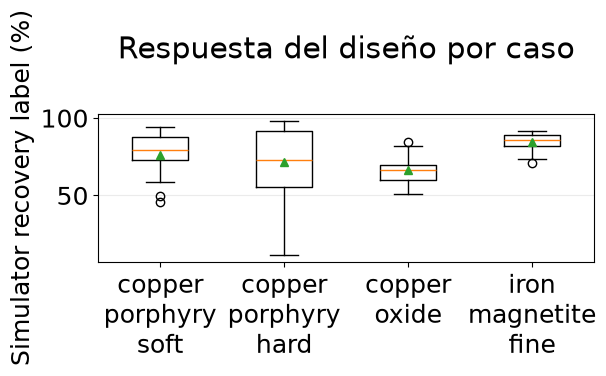

In [11]:
# Compara las etiquetas simuladas de recuperación según la unidad de evaluación agrupada.
frame = pd.DataFrame({"case": case_of, "recovery_pct": y[:, 0]})
labels = list(dict.fromkeys(frame["case"].tolist()))
series = [frame.loc[frame["case"] == label, "recovery_pct"].to_numpy() for label in labels]
fig, ax = plt.subplots(figsize=(6.4, 3.8))
ax.boxplot(series, tick_labels=[label.replace("_", "\n") for label in labels], showmeans=True)
ax.set(
    ylabel="Simulator recovery label (%)",
    title="Respuesta del diseño por caso",
)
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()


Las cajas resumen etiquetas de recuperación del simulador por caso de autoría antes del ajuste. Su solapamiento muestra dónde una respuesta global puede confundir casos; medianas distintas revelan estructura que una partición aleatoria puede filtrar. Cada caja contiene estados de diseño, no muestras independientes de una población de menas.

## Referencias

- https://doi.org/10.1023/A:1010933404324
- https://doi.org/10.1023/A:1010933404324
- https://doi.org/10.1214/aos/1013203451
- https://doi.org/10.1017/CBO9780511790423